# Monte Carlo Control: Learning Blackjack from Episodes

**Family:** Reinforcement learning | **Level:** Intermediate | **Dataset:** `Blackjack-v1` | **Runs on:** CPU, about 2 minute(s)

Learn values by averaging complete episodes without a model.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- First visit Monte Carlo estimation
- Exploration with epsilon soft policies
- Why returns have high variance
- How to compare a policy with a baseline using a confidence interval

**Prerequisites:**

- Probability basics
- Markov decision processes

**Skills you will have afterwards:**

- Run several seeds
- Report learning curves with spread
- Compare with a baseline policy

## 2. Real-World Problem

**Context.** Blackjack has a known rule set, but the transition probabilities depend on the shuffled deck.

**The problem.** Learn when to hit or stick from sampled games.

**Why it matters.** Model free learning works when the model is too complex to write down.

**Why machine learning.** The best action depends on player sum, dealer card and usable ace.

**Why this algorithm.** Episodes are short and end with a clear reward, which suits Monte Carlo.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Reinforcement Learning: An Introduction (2nd ed.)

- **Type:** foundational paper
- **Authors:** Sutton, R. S. and Barto, A. G.
- **Year and venue:** 2018, MIT Press
- **DOI or URL:** http://incompleteideas.net/book/the-book-2nd.html
- **Verification:** not verified in build environment
- **Research objective:** Textbook covering dynamic programming, Monte Carlo, TD, policy gradient.
- **Methodology:** Textbook.
- **Dataset:** Not applicable.
- **Main findings:** Reference text for this section.
- **Limitations:** Textbook, not an experiment.

**Relationship to this notebook.** Sutton and Barto (not verified in the build environment, check before citing) use blackjack as the standard Monte Carlo example. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Return.** $G_t = \sum_{k=0}^{T-t-1}\gamma^k R_{t+k+1}$.

**Value estimate.** $V(s) = \text{mean}\{G_t : S_t = s\}$ over first visits. Incremental form: $Q(s,a) \leftarrow Q(s,a) + \frac{1}{N(s,a)}\big(G - Q(s,a)\big)$.

**Control.** Act $\varepsilon$-greedily with respect to $Q$ so that every action keeps being tried. Policy improvement is the greedy step on the estimated $Q$.

**Variance.** $G$ sums many random rewards, so the estimate converges slowly. Standard error falls as $1/\sqrt{N}$.

**Limits.** Needs episodes that end, high variance, slow in large state spaces.

## 5. Dataset Introduction

**Blackjack-v1** (Gymnasium, `toy_text`). State is (player sum 4 to 21, dealer showing card 1 to 10, usable ace 0 or 1), 2 actions (stick, hit). Reward +1 win, 0 draw, -1 loss, with no natural bonus. The environment samples from an infinite deck. There is no dataset.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython.display import display

from ml_lab.rl import tabular, deep
from ml_lab.evaluation import evaluate_policy
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "monte_carlo"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()
print("gymnasium", gym.__version__)

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
gymnasium 1.4.0


## 6. Exploratory Data Analysis

There is no dataset. We inspect the environment: observation and action spaces, rewards and a random policy baseline. 

In [2]:
env = gym.make("Blackjack-v1", sab=False)
print("observation space:", env.observation_space, "| actions:", env.action_space)
state, _ = env.reset(seed=0)
print("example start state (player sum, dealer card, usable ace):", state)

observation space: Tuple(Discrete(32), Discrete(11), Discrete(2)) | actions: Discrete(2)
example start state (player sum, dealer card, usable ace): (11, 10, 0)


## 7. Data Preprocessing

No preprocessing. States are tuples used as dictionary keys. Training uses seeds from 0, evaluation uses separate seeds from 10 000 000.

In [3]:
def new_env():
    return gym.make("Blackjack-v1", sab=False)
print("ready")

ready


## 8. Algorithm Implementation

### 8.1 Concept

Play a full game, then credit every visited state action pair with the final reward. After many games the averages approach the true values.

### 8.2 Python implementation from scratch

First visit Monte Carlo control with an epsilon soft policy. In Blackjack each state action pair appears at most once per game, so first visit and every visit are the same.

In [4]:
def mc_control(episodes, epsilon=0.1, seed=0):
    rng = np.random.default_rng(seed)
    env = new_env()
    Q, N = {}, {}
    env.reset(seed=seed)
    curve = []
    for ep in range(episodes):
        state, _ = env.reset()
        trajectory, done = [], False
        while not done:
            q = Q.setdefault(state, np.zeros(2))
            action = int(rng.integers(2)) if rng.random() < epsilon else int(q.argmax())
            nxt, reward, term, trunc, _ = env.step(action)
            trajectory.append((state, action))
            state, done = nxt, term or trunc
        for s, a in trajectory:
            N[(s, a)] = N.get((s, a), 0) + 1
            Q[s][a] += (reward - Q[s][a]) / N[(s, a)]
        curve.append(reward)
    env.close()
    return Q, np.array(curve)
print(inspect.getsource(mc_control)[:300], "...")

def mc_control(episodes, epsilon=0.1, seed=0):
    rng = np.random.default_rng(seed)
    env = new_env()
    Q, N = {}, {}
    env.reset(seed=seed)
    curve = []
    for ep in range(episodes):
        state, _ = env.reset()
        trajectory, done = [], False
        while not done:
            q  ...


### 8.3 Library implementation

The algorithm is implemented in `src/ml_lab/rl` without an RL library. Gymnasium supplies only the environment.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `episodes` | Number of games. |
| `epsilon` | Exploration probability. |
| `gamma` | 1 here, episodes are short. |

## 9. Model Training

Train with 5 seeds and 200 000 games each. Epsilon is 0.1.

In [5]:
import time
t0 = time.time()
runs = []
for seed in range(5):
    Q, rewards = mc_control(200000, seed=seed)
    runs.append((Q, rewards))
    print("seed", seed, "states seen", len(Q), "| mean reward of last 20000 training games (with exploration)", round(float(rewards[-20000:].mean()), 4))
print("seconds:", round(time.time() - t0, 1))

seed 0 states seen 280 | mean reward of last 20000 training games (with exploration) -0.1027


seed 1 states seen 280 | mean reward of last 20000 training games (with exploration) -0.0871


seed 2 states seen 280 | mean reward of last 20000 training games (with exploration) -0.0896


seed 3 states seen 280 | mean reward of last 20000 training games (with exploration) -0.0882


seed 4 states seen 280 | mean reward of last 20000 training games (with exploration) -0.0854
seconds: 41.8


## 10. Evaluation

Return is the sum of rewards in an episode. We report the mean return of the final policy over fresh evaluation episodes (seeds not used in training), the spread across training seeds, and the same number for a random policy as a floor. RL results change a lot between seeds, so every headline number comes with its spread.

In [6]:
def run_policy(policy, games=50000, seed0=10_000_000):
    env = new_env()
    rewards = []
    for i in range(games):
        s, _ = env.reset(seed=seed0 + i)
        done = False
        while not done:
            s, r, term, trunc, _ = env.step(policy(s))
            done = term or trunc
        rewards.append(r)
    return np.array(rewards)
stick20 = run_policy(lambda s: 0 if s[0] >= 20 else 1)
rng_eval = np.random.default_rng(0)
random_pol = run_policy(lambda s: int(rng_eval.integers(2)))
learned = []
for Q, _ in runs:
    learned.append(run_policy(lambda s, Q=Q: int(Q[s].argmax()) if s in Q else 0))
means = np.array([r.mean() for r in learned])
se = np.mean([r.std(ddof=1) / np.sqrt(len(r)) for r in learned])
table = pd.DataFrame({"mean_return": [means.mean(), stick20.mean(), random_pol.mean()],
                      "std_error": [se, stick20.std(ddof=1) / np.sqrt(len(stick20)), random_pol.std(ddof=1) / np.sqrt(len(random_pol))]},
                     index=["learned (mean of 5 seeds)", "stick on 20 or more", "random"])
display(table.round(4))
print("learned policy mean return per seed:", np.round(means, 4), "| spread across seeds:", round(float(means.std(ddof=1)), 4))
METRICS = {"eval_mean_return": float(means.mean()), "eval_std_across_seeds": float(means.std(ddof=1)), "eval_std_error": float(se),
           "stick20_mean_return": float(stick20.mean()), "random_mean_return": float(random_pol.mean())}
CONFIG = {"episodes": 200000, "epsilon": 0.1, "seeds": 5, "eval_games": 50000}
EXTRA = {"per_seed_eval": [float(m) for m in means]}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="reinforcement_learning", algorithm="MonteCarloControl", dataset="Blackjack-v1",
                          task="control", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,mean_return,std_error
learned (mean of 5 seeds),-0.0524,0.0043
stick on 20 or more,-0.3511,0.0040
random,-0.3895,0.0040


learned policy mean return per seed: [-0.0503 -0.05   -0.0549 -0.0521 -0.0544] | spread across seeds: 0.0023
saved: /home/claude/open-python/experiments/results/monte_carlo.json


,metric
eval_mean_return,-0.0524
eval_std_across_seeds,0.0023
eval_std_error,0.0043
stick20_mean_return,-0.3511
random_mean_return,-0.3895


## 11. Visualization

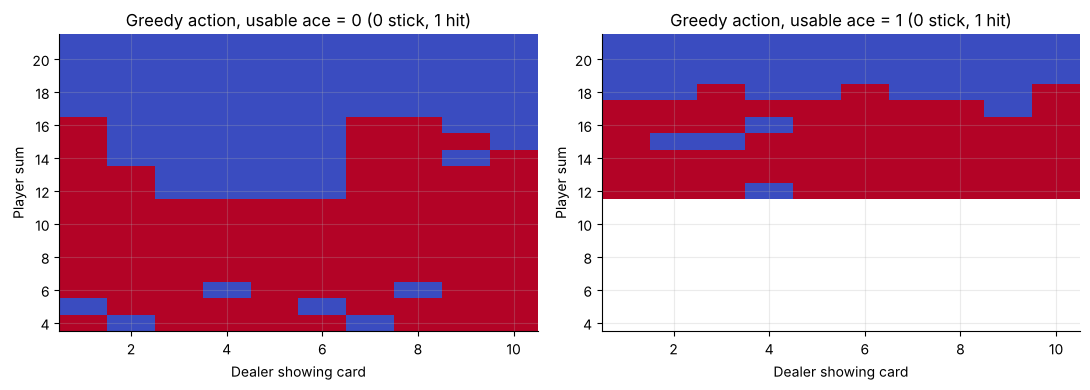

In [7]:
Q = runs[0][0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, ace in zip(axes, [0, 1]):
    grid = np.full((18, 10), np.nan)
    for (p, d, a), q in Q.items():
        if a == ace and 4 <= p <= 21:
            grid[p - 4, d - 1] = int(q.argmax())
    im = ax.imshow(grid, origin="lower", cmap="coolwarm", extent=[0.5, 10.5, 3.5, 21.5], aspect="auto")
    ax.set_xlabel("Dealer showing card"); ax.set_ylabel("Player sum"); ax.set_title(f"Greedy action, usable ace = {ace} (0 stick, 1 hit)")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "policy"); plt.show()

## 12. Interpretation

The learned rule should stick on high sums and hit on low sums, with the threshold depending on the dealer card.

In [8]:
no_ace = {s[0]: int(q.argmax()) for s, q in Q.items() if s[1] == 10 and s[2] == 0}
print("action by player sum when the dealer shows 10, no usable ace (0 stick, 1 hit):", dict(sorted(no_ace.items())))

action by player sum when the dealer shows 10, no usable ace (0 stick, 1 hit): {4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1, 10: 1, 11: 1, 12: 1, 13: 1, 14: 1, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0, 20: 0, 21: 0}


## 13. Experiments and Challenges

### Experiment 1: Number of training games

Learned policy return against games, one seed, 20000 evaluation games.

In [9]:
for n in [1000, 10000, 100000]:
    Qn, _ = mc_control(n, seed=0)
    r = run_policy(lambda s, Qn=Qn: int(Qn[s].argmax()) if s in Qn else 0, games=20000)
    print(f"{n} games: mean return {r.mean():.4f} +- {r.std(ddof=1) / np.sqrt(len(r)):.4f}")

1000 games: mean return -0.1595 +- 0.0067


10000 games: mean return -0.0910 +- 0.0068


100000 games: mean return -0.0495 +- 0.0067


### Experiment 2: Exploration rate

Epsilon 0.01, 0.1 and 0.3 with 50 000 games.

In [10]:
for eps in [0.01, 0.1, 0.3]:
    Qe, _ = mc_control(50000, epsilon=eps, seed=0)
    r = run_policy(lambda s, Qe=Qe: int(Qe[s].argmax()) if s in Qe else 0, games=20000)
    print(f"epsilon={eps}: mean return {r.mean():.4f}")

epsilon=0.01: mean return -0.1109


epsilon=0.1: mean return -0.0609


epsilon=0.3: mean return -0.0605


### Experiment 3: Variance of the estimate

Standard deviation of a single game reward and the resulting number of games for a given precision.

In [11]:
sd = learned[0].std(ddof=1)
print("std of one game reward:", round(float(sd), 3))
for target in [0.01, 0.005]:
    print(f"games needed for a standard error of {target}: about {int((sd / target) ** 2)}")

std of one game reward: 0.953
games needed for a standard error of 0.01: about 9084
games needed for a standard error of 0.005: about 36337


### Exercises for learners

1. Repeat with a different set of seeds and report the spread.
2. Change the discount factor and describe what happens to the learned behaviour.
3. Change one hyperparameter by a factor of 10 and compare learning curves.

## 14. Research Discussion

The textbook treatment predicts slow convergence from high variance. The games needed for a precise comparison, computed above, make that concrete: small differences between policies need many games to see.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use off policy evaluation with importance sampling, or TD methods to cut variance.

**Research limitations.** One dataset and one seed for the headline numbers. Few seeds (see the notebook), small environments, and no hyperparameter search beyond the experiments shown.

## 15. Summary and Further Reading

**Key takeaways**

- MC averages complete episodes.
- Epsilon soft policies keep exploring.
- Report standard errors for policy comparisons.

**Use cases.** Games, simulators with no model.

**Limitations.** High variance, episodic tasks only.

**Recommended next notebook.** Temporal difference learning.

**Further reading.** See `references.md` in this folder.